# Gradient Boosting for Classification
### A walkthrough of `GradientBoost.py` and `DecisionTreeGradientBoost.py`

For classification, gradient boosting keeps **one raw score per class**, $F_k(x)$, turns the scores into probabilities with the **softmax**, and trains regression trees on the negative gradient of the **cross-entropy (log-loss)**. Each round fits $K$ trees, one per class. Each tree's leaves take a **Newton step** that uses the curvature of the loss, $p(1-p)$, rather than just the mean residual.

This notebook derives every one of these pieces and checks them against the implementation in this folder. By the end you should be able to:

1. derive the softmax/cross-entropy gradient $p_k - y_k$ and its diagonal Hessian $p_k(1-p_k)$;
2. explain the log-prior start $F_k^{(0)} = \ln\pi_k$ and the Newton leaf value $\frac{K-1}{K}\,\frac{\sum r}{\sum p(1-p)}$;
3. show that in the binary case the implementation's two mirror-image trees per round amount to one Newton step on the log-odds;
4. trace two rounds of a 3-class problem by hand;
5. read probability surfaces, learning curves and calibration, and tune $\eta$, depth and the number of rounds.

Prerequisites: the [regression version](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb), which covers functional gradient descent, shrinkage and residual trees and is not re-derived here. The [AdaBoost notebook](../AdaBoost/AdaBoost_Walkthrough.ipynb) is useful for contrast with the exponential loss.

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while writing this notebook and since corrected in the `.py` files. Cells titled *⚠️ Note on the implementation* describe design choices that remain.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · [Regression Tree](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) · [Random Forest](../RandomForest/RandomForest_Walkthrough.ipynb) · [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) · [Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) · **Gradient Boosting (classification)** · [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)

**Notation.** $K$ classes. $y_{ik} = \mathbb{1}[y_i = k]$ is the one-hot target. $F_k(x)$ is the raw score of class $k$, and $p_k(x) = e^{F_k(x)}/\sum_j e^{F_j(x)}$ its softmax probability. $\pi_k$ is the training frequency of class $k$. For each sample and class, $r_{ik} = y_{ik} - p_{ik}$ is the pseudo-residual, $g_{ik} = p_{ik} - y_{ik}$ the gradient, and $h_{ik} = p_{ik}(1 - p_{ik})$ the (diagonal) Hessian. $\eta$ is the learning rate and $T$ the number of rounds; each round adds $K$ trees.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "GradientBoost.py").exists(), "Open/run this notebook from inside the GradientBoostClassification/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from this folder, never copied into the notebook
from GradientBoost import GradientBoostingClassifier
from DecisionTreeGradientBoost import DecisionTreeRegressor as NewtonTree

print("GradientBoostingClassifier methods:", [k for k in vars(GradientBoostingClassifier) if not k.startswith("__")])
print("Newton regression tree methods:   ", [k for k in vars(NewtonTree) if not k.startswith("__")])

def leaf_of(x, node):                       # Illustration helper: the leaf (Node) a row reaches
    while node.value is None:
        node = node.left if x[node.feature_index] <= node.threshold else node.right
    return node

def log_loss(P, y):                         # Illustration helper: mean cross-entropy, y = integer labels
    return -np.mean(np.log(np.clip(P[np.arange(len(y)), y.astype(int)], 1e-15, 1)))

GradientBoostingClassifier methods: ['softmax', 'fit', 'predict_proba', 'predict', 'get_staged_predictions', 'get_feature_importance', 'calculate_tree_importance']
Newton regression tree methods:    ['build_tree', 'get_best_split', 'variance_reduction', 'split', 'calculate_leaf_value', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem: class probabilities, not just labels

The task is $K$-class classification, but now we want more than a label: an estimate of the class **probabilities** $P(y = k \mid x)$. Probabilities let us rank, threshold at any operating point, and quantify uncertainty. The natural loss for probabilities is the **cross-entropy** (negative log-likelihood):

$$
L = -\sum_{i=1}^n \sum_{k=0}^{K-1} y_{ik}\,\ln p_k(x_i) = -\sum_i \ln p_{y_i}(x_i). \tag{1}
$$

It rewards confident correct predictions and punishes confident wrong ones heavily, because $-\ln p \to \infty$ as $p \to 0$. Unlike AdaBoost's exponential loss, it grows only **linearly** in the margin for badly misclassified points, which makes it more robust to label noise.

The running example has three overlapping Gaussian classes.

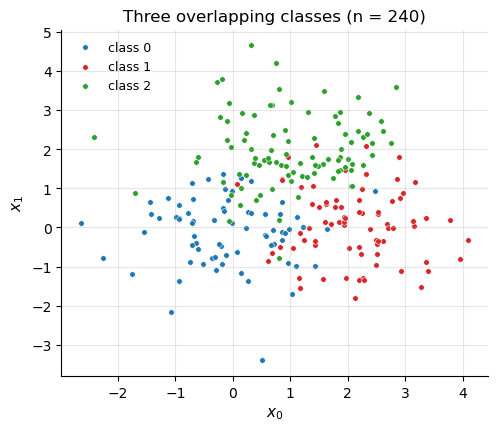

class frequencies π_k: [0.296 0.317 0.388]


In [4]:
centers = [[0.0, 0.0], [2.2, 0.0], [1.1, 1.9]]
X_tr, y_tr = make_blobs(240, centers=centers, std=0.9)
X_te, y_te = make_blobs(1000, centers=centers, std=0.9)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for k in range(3):
    ax.scatter(X_tr[y_tr == k, 0], X_tr[y_tr == k, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
ax.set(title="Three overlapping classes (n = 240)", xlabel="$x_0$", ylabel="$x_1$"); ax.legend(); plt.show()
print("class frequencies π_k:", np.round(np.bincount(y_tr.astype(int)) / len(y_tr), 3))

The classes overlap, so near the middle no classifier can be certain. A good probabilistic model should report probabilities near $\tfrac13$ there and near 1 deep inside each cluster.

## 3. Why gradient boosting with softmax fits this problem

- **A score per class.** The model keeps $K$ additive functions $F_k(x) = F_k^{(0)} + \eta\sum_t f_{t,k}(x)$, one per class, each a sum of regression trees. The softmax turns them into a probability vector that always lies on the simplex.
- **Any differentiable loss.** The [regression notebook](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) showed that boosting fits each tree to the loss's negative gradient. With cross-entropy the gradient is simply $y - p$ (§4.2), the gap between the one-hot target and the predicted probability.
- **Second-order leaves.** The log-loss has non-constant curvature, so the best leaf step is a Newton step that divides by $\sum p(1-p)$ (§4.4). Regions where the model is already confident ($p$ near 0 or 1, small curvature) get larger raw-score updates.
- **Versus AdaBoost.** The same additive, bias-reducing idea, but with log-loss instead of exponential loss, real-valued trees instead of class votes, and probability outputs.

## 4. Core concepts, theory and math

### 4.1 Softmax and the log-prior start

**Concept.** Raw scores are unconstrained real numbers. The softmax maps them to probabilities. Before any tree, the best constant model predicts the class frequencies.

**Math.** The softmax is

$$
p_k = \frac{e^{F_k}}{\sum_{j} e^{F_j}} . \tag{2}
$$

It is **invariant to adding the same constant to every score**: multiplying numerator and denominator by $e^{c}$ changes nothing. The code subtracts $\max_j F_j$ before exponentiating, which uses this invariance to avoid overflow. For the start, the constant probabilities that minimise Eq. (1) are the class frequencies $\pi_k$. This is the maximum-likelihood estimate of a categorical distribution: minimise $-\sum_k n_k \ln p_k$ subject to $\sum_k p_k = 1$, where the Lagrangian gives $n_k/p_k = \lambda$, so $p_k = n_k / n$. Setting

$$
F_k^{(0)} = \ln \pi_k \quad\Longrightarrow\quad p_k^{(0)} = \frac{\pi_k}{\sum_j \pi_j} = \pi_k , \tag{3}
$$

so the log-prior start reproduces the class frequencies exactly. Any constant shift of all $F_k^{(0)}$ would too.

**Your implementation and check.**

In [5]:
gbc0 = GradientBoostingClassifier(n_estimators=0); gbc0.fit(X_tr, y_tr)
pi = np.bincount(y_tr.astype(int)) / len(y_tr)
print("init_raw_scores_ (ln π_k):", np.round(gbc0.init_raw_scores_, 4), " ln π:", np.round(np.log(pi), 4))
P0 = gbc0.predict_proba(X_te[:3])
print("predict_proba with no trees:", np.round(P0, 4))
assert np.allclose(gbc0.init_raw_scores_, np.log(pi)) and np.allclose(P0, pi)
S = rng.normal(size=(5, 3)) * 50
assert np.allclose(gbc0.softmax(S), gbc0.softmax(S + 1000.0)) and np.allclose(gbc0.softmax(S).sum(axis=1), 1)
print("✓ log-prior start reproduces π (Eq. 3); softmax is shift-invariant and stable even for scores ~ ±1000")

init_raw_scores_ (ln π_k): [-1.218  -1.1499 -0.948 ]  ln π: [-1.218  -1.1499 -0.948 ]
predict_proba with no trees: [[0.2958 0.3167 0.3875]
 [0.2958 0.3167 0.3875]
 [0.2958 0.3167 0.3875]]
✓ log-prior start reproduces π (Eq. 3); softmax is shift-invariant and stable even for scores ~ ±1000


### 4.2 The gradient of cross-entropy with softmax: $p - y$

**Math.** First, the derivative of the softmax. From Eq. (2), $\frac{\partial p_j}{\partial F_k} = p_j(\delta_{jk} - p_k)$, where $\delta_{jk}$ is 1 if $j = k$ and 0 otherwise. For one sample, $L_i = -\sum_j y_{ij}\ln p_j$, so

$$
\frac{\partial L_i}{\partial F_k} = -\sum_j \frac{y_{ij}}{p_j}\,p_j(\delta_{jk} - p_k) = -\sum_j y_{ij}\delta_{jk} + p_k\sum_j y_{ij} = -y_{ik} + p_k , \tag{4}
$$

using $\sum_j y_{ij} = 1$ (one-hot). The **negative gradient** is therefore the pseudo-residual

$$
r_{ik} = y_{ik} - p_{ik} \in (-1, 1),
$$

positive when the model under-predicts class $k$ for sample $i$, and negative when it over-predicts.

**Illustration and check.** Finite differences of the per-sample loss, against Eq. (4).

In [6]:
# Illustration only — finite-difference check of Eq. (4) for one sample
F_i = rng.normal(size=3); y_i = np.array([0.0, 1.0, 0.0])
Li = lambda F: -np.sum(y_i * np.log(gbc0.softmax(F[None, :])[0]))
p_i = gbc0.softmax(F_i[None, :])[0]
for k in range(3):
    e = np.zeros(3); e[k] = 1e-6
    fd = (Li(F_i + e) - Li(F_i - e)) / 2e-6
    print(f"k = {k}: dL/dF_k ≈ {fd:+.6f}   p_k - y_k = {p_i[k] - y_i[k]:+.6f}")
    assert np.isclose(fd, p_i[k] - y_i[k], atol=1e-6)

k = 0: dL/dF_k ≈ +0.167200   p_k - y_k = +0.167200
k = 1: dL/dF_k ≈ -0.527775   p_k - y_k = -0.527775
k = 2: dL/dF_k ≈ +0.360576   p_k - y_k = +0.360576


### 4.3 The Hessian, and the residual trees

**Math.** Differentiating Eq. (4) again gives $\frac{\partial^2 L_i}{\partial F_k\,\partial F_j} = \frac{\partial p_k}{\partial F_j} = p_k(\delta_{kj} - p_j)$. The **diagonal** entries are

$$
h_{ik} = \frac{\partial^2 L_i}{\partial F_k^2} = p_{ik}(1 - p_{ik}), \tag{5}
$$

largest ($\tfrac14$) when the model is unsure ($p = \tfrac12$), and near 0 when it is confident. The off-diagonal entries, $-p_{ik}p_{ij}$, couple the classes; the per-class trees ignore them, which is the reason for the correction factor in §4.4.

**The trees.** In round $t$, for each class $k$ separately, the code fits a regression tree to the residuals $r_{ik}$ using **variance reduction** (exactly as in the regression notebook), with midpoint thresholds. The probabilities $p_{ik}$ are carried along the recursion (`split` partitions them with the rows) so that the leaves can use them. They are not used to choose the splits.

> ⚠️ **Note on the implementation — splits ignore the curvature.**
> The split criterion is plain variance reduction on the residuals, which treats every sample as equally important. Friedman's algorithm also chooses splits on the residuals (with a slightly different "Friedman MSE" criterion in scikit-learn). XGBoost instead scores splits with a **Hessian-weighted** gain derived from the second-order expansion of the loss, so that confident samples (small $h$) count less. The [XGBoost notebook](../XGBoost/XGBoost_Walkthrough.ipynb) derives that gain. Here the curvature enters only through the leaf values.

### 4.4 Newton leaf values and the $(K-1)/K$ factor

**Math.** Consider one leaf $\ell$ of the tree for class $k$, and a constant step $v$ added to $F_k$ for every sample in it. A second-order Taylor expansion of the loss in $v$ gives

$$
\sum_{i\in\ell} L_i(F_k + v) \approx \sum_{i\in\ell} \Big(L_i + g_{ik}\,v + \tfrac12 h_{ik} v^2\Big),
$$

which is minimised at the **Newton step**

$$
v^{\text{Newton}} = -\frac{\sum_{i\in\ell} g_{ik}}{\sum_{i\in\ell} h_{ik}} = \frac{\sum_{i\in\ell} r_{ik}}{\sum_{i\in\ell} p_{ik}(1-p_{ik})} . \tag{6}
$$

Compare this with the regression case, where $h = 1$ and the Newton step was the mean residual. Here, leaves full of confident samples (small $\sum h$) take *bigger* steps in raw-score space, because pushing an already confident probability further requires a large change in $F$.

Friedman's multiclass algorithm (2001, Algorithm 6) multiplies Eq. (6) by $\frac{K-1}{K}$:

$$
v_\ell = \frac{K-1}{K}\cdot\frac{\sum_{i\in\ell} r_{ik}}{\sum_{i\in\ell} p_{ik}(1-p_{ik})} . \tag{7}
$$

*Why?* The $K$ per-class Newton steps are computed independently, using only the diagonal of the Hessian. But the scores are only determined up to a common constant (softmax invariance, §4.1), and the true Hessian has negative off-diagonal entries $-p_kp_j$ linking the classes. Friedman's symmetric derivation, which imposes $\sum_k F_k = 0$, shrinks each diagonal step by $(K-1)/K$ to compensate. For $K = 2$ the factor is $\tfrac12$, which §4.5 shows gives exactly the standard binary log-odds Newton step.

**Your implementation and check.** `calculate_leaf_value(residuals, probabilities)` against Eq. (7), directly and inside a fitted model's first-round trees.

In [7]:
nt = NewtonTree(n_classes=3)
r_ = rng.uniform(-1, 1, 12); p_ = rng.uniform(0.05, 0.95, 12)
print(f"calculate_leaf_value = {nt.calculate_leaf_value(r_, p_):.6f}   Eq.(7) = {(2/3) * r_.sum() / np.sum(p_ * (1 - p_)):.6f}")
assert np.isclose(nt.calculate_leaf_value(r_, p_), (2 / 3) * r_.sum() / np.sum(p_ * (1 - p_)))

# Inside a fitted model: round 1 starts from the log-prior probabilities π
gbc1 = GradientBoostingClassifier(n_estimators=1, max_depth=2, learning_rate=0.5); gbc1.fit(X_tr, y_tr)
for k in range(3):
    tree_k = gbc1.trees[k][0]; r_k = (y_tr == k) - pi[k]; p_k = np.full(len(y_tr), pi[k])
    groups = {}
    for x_i, ri, pi_i in zip(X_tr, r_k, p_k):
        groups.setdefault(id(leaf_of(x_i, tree_k.root)), []).append((ri, pi_i))
    for nd in iter_nodes(tree_k.root):
        if nd.value is not None:
            rr, pp = np.array(groups[id(nd)]).T
            assert np.isclose(nd.value, (2 / 3) * rr.sum() / np.sum(pp * (1 - pp)))
print("✓ every leaf of every round-1 tree equals (K-1)/K · Σr / Σp(1-p) over the samples it contains (Eq. 7)")

calculate_leaf_value = -0.242658   Eq.(7) = -0.242658
✓ every leaf of every round-1 tree equals (K-1)/K · Σr / Σp(1-p) over the samples it contains (Eq. 7)


### 4.5 The binary case: two mirror-image trees, one log-odds Newton step

**Math.** With $K = 2$, $p_1 = 1 - p_0$, so the residuals satisfy $r_{i1} = -r_{i0}$, and the Hessians are equal, $p_0(1-p_0) = p_1(1-p_1)$. Variance reduction does not change when every target is negated, so the two trees choose **the same splits**, and by Eq. (7) their leaves are exact negatives: $v_1 = -v_0$. What matters for the probabilities is the log-odds $F_1 - F_0$, which changes in each leaf by

$$
\eta\,(v_1 - v_0) = 2\eta\, v_1 = 2\eta\cdot\tfrac12\cdot\frac{\sum r_{i1}}{\sum p_{i1}(1-p_{i1})} = \eta\,\frac{\sum (y_i - p_i)}{\sum p_i(1-p_i)},
$$

which is exactly the Newton step of standard binary logistic boosting (the "binomial deviance" used by scikit-learn for $K=2$). So the $(K-1)/K$ factor makes the two-class model agree with the usual binary algorithm.

In [8]:
Xb, yb = make_moons(200, noise=0.3)
gbin = GradientBoostingClassifier(n_estimators=3, max_depth=2, learning_rate=0.5); gbin.fit(Xb, yb)
for t in range(3):
    t0, t1 = gbin.trees[0][t], gbin.trees[1][t]
    assert np.allclose(t0.predict(Xb), -t1.predict(Xb))
    assert [(n.feature_index, n.threshold) for n in iter_nodes(t0.root) if n.value is None] == \
           [(n.feature_index, n.threshold) for n in iter_nodes(t1.root) if n.value is None]
# the log-odds update of round 1 equals the binary Newton step Σ(y-p)/Σp(1-p) per leaf
p1 = np.full(len(yb), np.mean(yb)); r = yb - p1; groups = {}
for x_i, ri, pi_i in zip(Xb, r, p1):
    groups.setdefault(id(leaf_of(x_i, gbin.trees[1][0].root)), []).append((ri, pi_i))
for nd in iter_nodes(gbin.trees[1][0].root):
    if nd.value is not None:
        rr, pp = np.array(groups[id(nd)]).T
        assert np.isclose(2 * nd.value, rr.sum() / np.sum(pp * (1 - pp)))
print("✓ binary case: identical splits, mirror-image leaves, and v1 - v0 = Σ(y-p)/Σp(1-p): one log-odds Newton step")

✓ binary case: identical splits, mirror-image leaves, and v1 - v0 = Σ(y-p)/Σp(1-p): one log-odds Newton step


> ⚠️ **Note on the implementation — binary problems fit two trees per round.**
> Because the two trees are exact mirror images, fitting both is redundant: half the training time is spent recomputing the negative of a tree that is already known. Production libraries fit a single tree on the log-odds when $K = 2$. The results are the same, as shown above.

> 🔧 **Fixed in the code — `print_tree()` crashed.**
> *Originally:* `print_tree` defaulted to `self.root1`, a misspelling, so calling it without an argument raised `AttributeError: 'DecisionTreeRegressor' object has no attribute 'root1'`.
> *Now:* it defaults to `self.root`. The same edit replaced `if not tree` / `!= None` with identity tests. It also fixed the tree's `KeyError` when a node's features are all constant (which now makes a leaf), let a node whose residuals are all equal become a leaf without a search, removed the global `np.random.seed` calls from the tree and the booster (nothing here is random), made `max_depth=None` mean unlimited, and made `get_staged_predictions` loop over the rounds actually fitted.

In [9]:
gbin.trees[1][0].print_tree()          # used to raise AttributeError: ... no attribute 'root1'

X_1 <= 0.13225981849005786 ? 0.11
    left:X_0 <= -0.4896368445576442 ? 0.0733
        left:-1.0
        right:0.9024
    right:X_0 <= 1.6138321202166228 ? 0.057
        left:-0.7426
        right:1.0


## 5. Implementation walkthrough, in the order the code runs

```
GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, min_samp_split=2)
  fit(X, Y):
     classes_, K; one-hot targets Y_onehot (n, K)
     init_raw_scores_[k] = ln π_k ;  raw = tile(init, n)                    Eq. (3)
     for t in range(n_estimators):
         P = softmax(raw)                                                    Eq. (2), once per round
         for k in range(K):
             r = Y_onehot[:, k] - P[:, k]                                    Eq. (4)
             tree = NewtonTree(min_samp_split, max_depth, n_classes=K)
             tree.fit(X, r, P[:, k])           variance-reduction splits; leaves Eq. (7)
             raw[:, k] += learning_rate * tree.predict(X)
  predict_proba(X): softmax(init + η Σ_t tree_{t,k}(X))     predict(X): argmax
```

**`softmax(raw_scores)` (GradientBoost.py, lines 60–66).** Eq. (2) with max-subtraction.

**`fit(X, Y)` (lines 68–137).** As above. Note that the probabilities are computed **once per round**, before the $K$ class trees are fitted. All $K$ trees of round $t$ see the same $p^{(t-1)}$ (as in Friedman's algorithm and scikit-learn), rather than each seeing the updates of the earlier classes in the same round. `self.trees` is a dict mapping class index → list of trees.

**`predict_proba(X)` (lines 139–154), `predict(X)` (lines 156–166), `get_staged_predictions(X)` (lines 168–191).** Accumulate the shrunken tree outputs onto the log-priors, apply softmax, and take the argmax. The staged version records the predicted labels after each round.

**`get_feature_importance(num_features)` (lines 193–228).** The sum of per-node `var_reduction` over all trees of all classes, divided by the number of trees. It is unweighted, as in the [regression notebook](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb#7.5-Feature-importance).

**`DecisionTreeGradientBoost.DecisionTreeRegressor` (lines 44–200).** `fit(X, Y, probabilities)` validates its inputs and concatenates features and residuals, keeping `probabilities` as a parallel array. `build_tree` and `get_best_split` scan midpoint thresholds by variance reduction, splitting the probabilities alongside the rows (`split`). `calculate_leaf_value` is Eq. (7), returning 0 if $\sum p(1-p) < 10^{-10}$ to avoid dividing by zero. Note that `get_best_split` keeps a candidate when `curr_var_reduction >= max_var_reduction`, so ties go to the **last** candidate scanned, unlike the other trees in this repo, which keep the first. This rarely matters, but it does mean equal-gain splits are resolved toward later features and larger thresholds.

**`Main.py`.** Compares this model with scikit-learn's `GradientBoostingClassifier` on the Wine data. For 3 classes both use the multinomial deviance with Friedman's leaf values, so their results should be close. scikit-learn's split criterion (Friedman MSE) and tie-breaking differ slightly. Not run here.

## 6. Worked numerical example: two rounds, three classes

Nine 1-D points with labels $0,0,0,1,1,2,1,2,2$; stumps; $\eta = 0.5$.

In [10]:
x_toy = np.arange(1, 10, dtype=float).reshape(-1, 1)
y_toy = np.array([0, 0, 0, 1, 1, 2, 1, 2, 2], dtype=float)
toy = GradientBoostingClassifier(n_estimators=2, max_depth=1, learning_rate=0.5); toy.fit(x_toy, y_toy)
Y1 = np.eye(3)[y_toy.astype(int)]
raw = np.tile(toy.init_raw_scores_, (9, 1))
print("π =", np.round(np.bincount(y_toy.astype(int)) / 9, 4), " F^(0) = ln π =", np.round(toy.init_raw_scores_, 4))
for t in range(2):
    P = toy.softmax(raw)
    print(f"\n=== round {t + 1}: probabilities p_k(x) at the start of the round")
    print(np.round(P, 3))
    for k in range(3):
        tree = toy.trees[k][t]; r = Y1[:, k] - P[:, k]; left = x_toy.ravel() <= tree.root.threshold
        num_L, den_L = r[left].sum(), np.sum(P[left, k] * (1 - P[left, k]))
        num_R, den_R = r[~left].sum(), np.sum(P[~left, k] * (1 - P[~left, k]))
        print(f" class {k}: residuals {np.round(r, 3)}")
        print(f"          stump x_0 <= {tree.root.threshold}:  left  (2/3)·{num_L:+.3f}/{den_L:.3f} = {tree.root.left.value:+.4f}"
              f"   right (2/3)·{num_R:+.3f}/{den_R:.3f} = {tree.root.right.value:+.4f}")
        assert np.isclose(tree.root.left.value, (2/3) * num_L / den_L) and np.isclose(tree.root.right.value, (2/3) * num_R / den_R)
        raw[:, k] += 0.5 * tree.predict(x_toy)
    P_new = toy.softmax(raw)
    print(f" after round {t + 1}: predicted classes {np.argmax(P_new, axis=1).tolist()}  (true {y_toy.astype(int).tolist()}),"
          f" log-loss {log_loss(P_new, y_toy):.4f}")
assert np.allclose(toy.softmax(raw), toy.predict_proba(x_toy))
print("\n✓ hand-computed probabilities after 2 rounds equal toy.predict_proba()")

π = [0.3333 0.3333 0.3333]  F^(0) = ln π = [-1.0986 -1.0986 -1.0986]

=== round 1: probabilities p_k(x) at the start of the round
[[0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]
 [0.333 0.333 0.333]]
 class 0: residuals [ 0.667  0.667  0.667 -0.333 -0.333 -0.333 -0.333 -0.333 -0.333]
          stump x_0 <= 3.5:  left  (2/3)·+2.000/0.667 = +2.0000   right (2/3)·-2.000/1.333 = -1.0000
 class 1: residuals [-0.333 -0.333 -0.333  0.667  0.667 -0.333  0.667 -0.333 -0.333]
          stump x_0 <= 3.5:  left  (2/3)·-1.000/0.667 = -1.0000   right (2/3)·+1.000/1.333 = +0.5000
 class 2: residuals [-0.333 -0.333 -0.333 -0.333 -0.333  0.667 -0.333  0.667  0.667]
          stump x_0 <= 5.5:  left  (2/3)·-1.667/1.111 = -1.0000   right (2/3)·+1.667/0.889 = +1.2500
 after round 1: predicted classes [0, 0, 0, 1, 1, 2, 2, 2, 2]  (true [0, 0, 0, 1, 1, 2, 1, 2, 2]), log-loss 0.6232

=== ro

Reading the two rounds:
- **Round 1.** The classes are equally frequent, so every probability starts at $\tfrac13$, and each residual is $+\tfrac23$ for the sample's own class and $-\tfrac13$ otherwise. Each class's stump isolates where that class lives: $x_0 \le 3.5$ for class 0, and $x_0 \le 5.5$ for class 2. Class 1 also chooses $x_0 \le 3.5$, which separates the region where it is absent. The leaf values are Newton steps, not means. On the left of class 0's stump, the three residuals sum to $2$ and each Hessian is $\tfrac13\cdot\tfrac23 = \tfrac29$, so $v = \tfrac23 \cdot 2/\tfrac23 = 2.0$, three times the mean residual. After adding half of each tree, the model gets every point right except $x = 7$ (class 1 in a class-2 region), and the log-loss falls from $\ln 3 \approx 1.10$ to $0.62$.
- **Round 2.** The probabilities now differ by region (for example $p_0 = 0.69$ on the left). The largest residual is class 1's $+0.66$ at $x = 7$, so the class-1 and class-2 trees both split at $x_0 \le 7.5$, raising class 1 and lowering class 2 to the left of 7.5. That fixes $x = 7$, but $x = 6$ (class 2) is now predicted as class 1. With stumps on one feature, two interleaved points cannot both be isolated in two rounds. Even so, the log-loss falls to $0.42$, because the probabilities become better calibrated overall.

Every leaf value printed above was asserted equal to Eq. (7), and the hand-computed probabilities equal `predict_proba`.

## 7. Visual experiments

### 7.1 Probability surfaces as rounds are added

Each pixel is coloured by mixing the three class colours in proportion to the predicted probabilities: pure colours mean confidence, and muddy mixtures mean uncertainty.

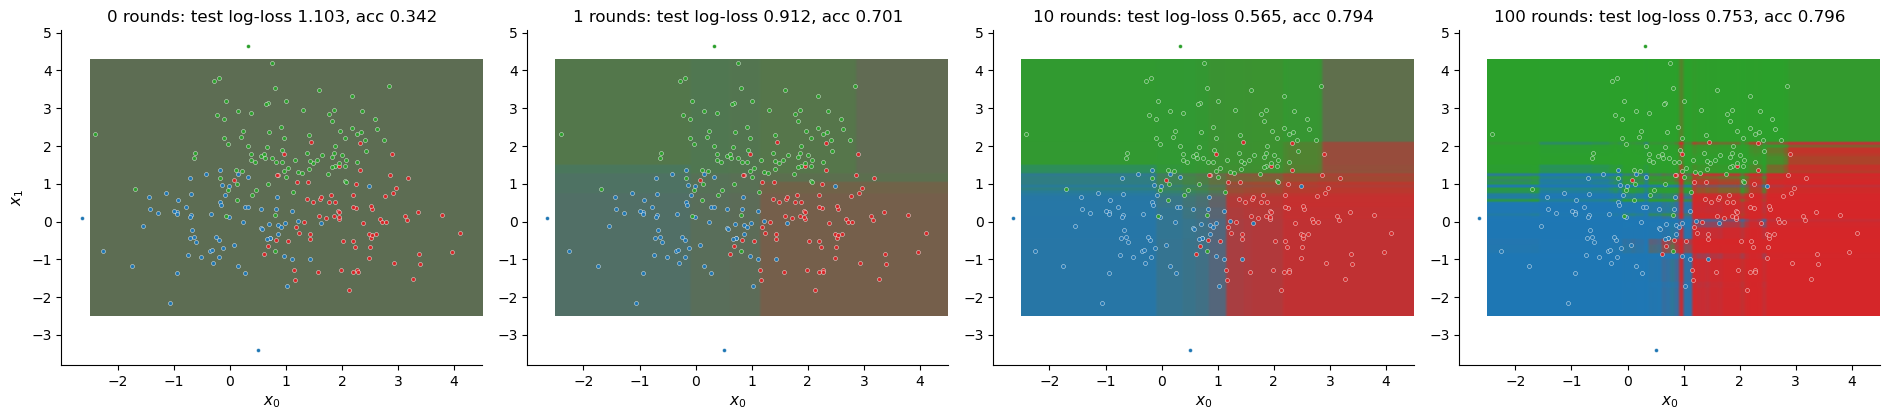

In [11]:
gbc = GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.2); gbc.fit(X_tr, y_tr)
g0_, g1_ = np.meshgrid(np.linspace(-2.5, 4.5, 90), np.linspace(-2.5, 4.3, 90)); grid = np.c_[g0_.ravel(), g1_.ravel()]
rgb = np.array([[0.12, 0.47, 0.71], [0.84, 0.15, 0.16], [0.17, 0.63, 0.17]])

def staged_proba(model, X, T):
    """Illustration only: probabilities after the first T rounds (same arithmetic as predict_proba)."""
    raw_ = np.tile(model.init_raw_scores_, (len(X), 1))
    for k in range(model.n_classes_):
        for tree in model.trees[k][:T]:
            raw_[:, k] += model.learning_rate * tree.predict(X)
    return model.softmax(raw_)
assert np.allclose(staged_proba(gbc, X_te, 100), gbc.predict_proba(X_te))

fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, T in zip(axes, [0, 1, 10, 100]):
    Pg = staged_proba(gbc, grid, T)
    ax.imshow((Pg @ rgb).reshape(g0_.shape + (3,)), origin="lower", extent=[-2.5, 4.5, -2.5, 4.3], aspect="auto")
    for k in range(3):
        ax.scatter(X_tr[y_tr == k, 0], X_tr[y_tr == k, 1], s=8, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.3)
    Pte = staged_proba(gbc, X_te, T)
    ax.set(title=f"{T} rounds: test log-loss {log_loss(Pte, y_te):.3f}, acc {np.mean(Pte.argmax(1) == y_te):.3f}", xlabel="$x_0$"); ax.grid(False)
axes[0].set_ylabel("$x_1$"); plt.tight_layout(); plt.show()

- **0 rounds.** A uniform muddy colour: the model predicts the class frequencies everywhere.
- **1 round.** Faint tints appear in the three regions. With $\eta = 0.2$, one round moves the scores only a little, so the probabilities are still close to the priors, although the argmax is already sensible.
- **10 rounds.** Clear regions with saturated colours deep inside each cluster, and mixed colours in the overlap zones, where the true label is uncertain. This is the best test log-loss of the four panels.
- **100 rounds.** Saturated colours almost everywhere, including thin stripes inside the overlap zones. The model has become **overconfident**: test accuracy is unchanged, but test log-loss is clearly worse, because confident mistakes are heavily penalised by Eq. (1).

### 7.2 Learning curves: log-loss and accuracy for several learning rates

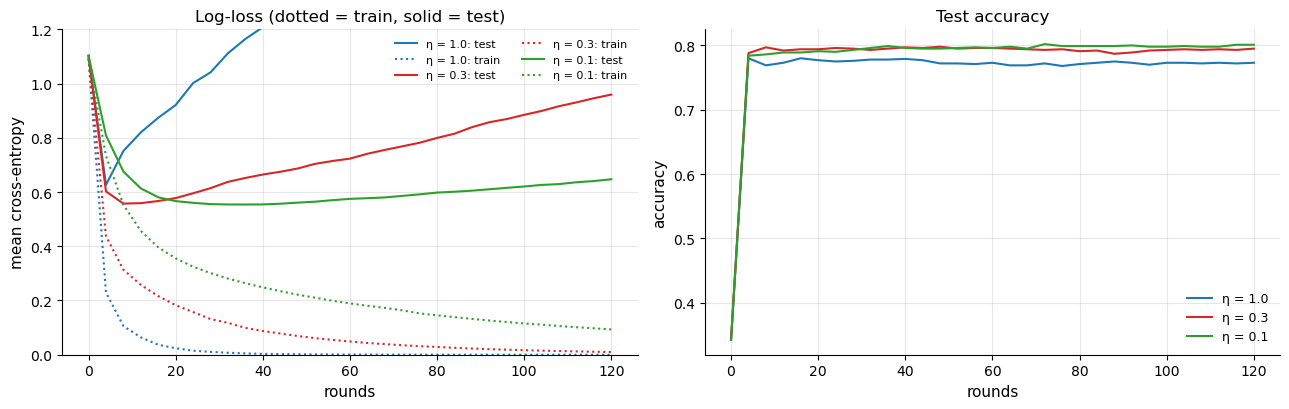

η = 1.0: best test log-loss 0.626 at 4 rounds, final 2.274;  test accuracy best 0.780, final 0.773
η = 0.3: best test log-loss 0.557 at 8 rounds, final 0.959;  test accuracy best 0.798, final 0.795
η = 0.1: best test log-loss 0.554 at 36 rounds, final 0.647;  test accuracy best 0.802, final 0.801


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
curves = {}
for eta_, col in zip([1.0, 0.3, 0.1], CLASS_COLORS):
    m_ = GradientBoostingClassifier(n_estimators=120, max_depth=2, learning_rate=eta_); m_.fit(X_tr, y_tr)
    Ts = np.arange(0, 121, 4)
    tr_ll = [log_loss(staged_proba(m_, X_tr, T), y_tr) for T in Ts]
    te_ll = [log_loss(staged_proba(m_, X_te, T), y_te) for T in Ts]
    te_acc = [np.mean(staged_proba(m_, X_te, T).argmax(1) == y_te) for T in Ts]
    curves[eta_] = (Ts, te_ll, te_acc)
    axes[0].plot(Ts, te_ll, color=col, label=f"η = {eta_}: test"); axes[0].plot(Ts, tr_ll, color=col, ls=":", label=f"η = {eta_}: train")
    axes[1].plot(Ts, te_acc, color=col, label=f"η = {eta_}")
axes[0].set(title="Log-loss (dotted = train, solid = test)", xlabel="rounds", ylabel="mean cross-entropy", ylim=(0, 1.2)); axes[0].legend(ncol=2, fontsize=8)
axes[1].set(title="Test accuracy", xlabel="rounds", ylabel="accuracy"); axes[1].legend()
plt.tight_layout(); plt.show()
for eta_, (Ts, te_ll, te_acc) in curves.items():
    i = int(np.argmin(te_ll))
    print(f"η = {eta_}: best test log-loss {te_ll[i]:.3f} at {Ts[i]} rounds, final {te_ll[-1]:.3f};  test accuracy best {max(te_acc):.3f}, final {te_acc[-1]:.3f}")

**Log-loss (left).** Training log-loss falls steadily, toward zero for $\eta = 1$. Test log-loss is U-shaped: its minimum comes after about 4, 8 and 36 rounds for $\eta = 1, 0.3, 0.1$ (again scaling roughly like $1/\eta$). After the minimum it rises, steeply for large $\eta$. **Accuracy (right)** barely moves after the first few rounds and stays near 0.80. Accuracy only checks the argmax, so it is blind to the growing overconfidence that the log-loss reveals. If you need probabilities, monitor the validation log-loss and stop early. A smaller $\eta$ gives a lower and much flatter log-loss minimum, so the result is less sensitive to exactly where you stop.

### 7.3 Are the probabilities trustworthy? A reliability diagram

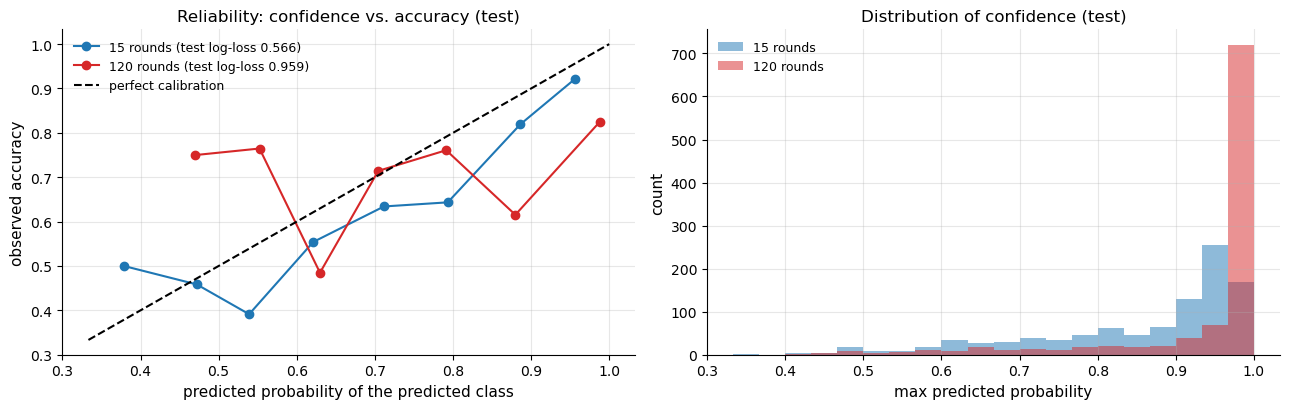

In [13]:
def reliability(P, y, bins=8):
    conf = P.max(axis=1); correct = P.argmax(axis=1) == y
    edges = np.linspace(1 / 3, 1, bins + 1); idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return [(conf[idx == b].mean(), correct[idx == b].mean(), np.sum(idx == b)) for b in range(bins) if np.any(idx == b)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for T, col in [(15, CLASS_COLORS[0]), (120, CLASS_COLORS[1])]:
    m_ = GradientBoostingClassifier(n_estimators=T, max_depth=2, learning_rate=0.3); m_.fit(X_tr, y_tr)
    P_ = m_.predict_proba(X_te); rel = np.array(reliability(P_, y_te))
    axes[0].plot(rel[:, 0], rel[:, 1], "o-", color=col, label=f"{T} rounds (test log-loss {log_loss(P_, y_te):.3f})")
    axes[1].hist(P_.max(axis=1), bins=20, range=(1/3, 1), alpha=0.5, color=col, label=f"{T} rounds")
axes[0].plot([1/3, 1], [1/3, 1], "k--", label="perfect calibration")
axes[0].set(title="Reliability: confidence vs. accuracy (test)", xlabel="predicted probability of the predicted class", ylabel="observed accuracy"); axes[0].legend()
axes[1].set(title="Distribution of confidence (test)", xlabel="max predicted probability", ylabel="count"); axes[1].legend()
plt.tight_layout(); plt.show()

A model is **calibrated** if, among the cases where it reports confidence $c$, it is right a fraction $c$ of the time; such points lie on the diagonal. After 15 rounds, near the log-loss minimum, the curve follows the diagonal roughly; the low-confidence bins hold few points and are noisy. Confidence is spread over the whole range, as it should be for overlapping classes. After 120 rounds, most test predictions claim more than 95% confidence (right panel), but the accuracy in that top bin is only about 82%. That is far below the diagonal, so the model is systematically overconfident. Remedies include early stopping, a smaller learning rate, or post-hoc calibration (temperature scaling, Platt or isotonic regression) on held-out data.

## 8. Hyperparameters

| Hyperparameter | Controls | Guidance |
|---|---|---|
| `n_estimators` ($T$) | rounds ($K$ trees each) | Watch the *validation log-loss*: it bottoms out earlier than accuracy, and overconfidence grows afterwards (§7.2–7.3). |
| `learning_rate` ($\eta$) | shrinkage | Smaller values give smoother curves and better minima but need more rounds; 0.05–0.3 is typical. |
| `max_depth` | interaction order per tree | 2–5 is typical; `None` = unlimited (risky). |
| `min_samp_split` | smallest splittable node | Regularises deep trees. |

## 9. Complexity and limitations

**Training:** $T \times K$ trees, each $O(D\,m\,n^2)$ with this split search, i.e. $O(T\,K\,D\,m\,n^2)$. Rounds are sequential, but the $K$ trees *within* a round are independent and could be fitted in parallel. **Prediction:** $O(T\,K\,D)$ per point.

| Limitation | Consequence | What production libraries do |
|---|---|---|
| $K$ trees per round even for $K = 2$ | twice the necessary work in binary problems (§4.5) | one log-odds tree when $K = 2$ |
| Splits by unweighted variance reduction | curvature used only in the leaves | Friedman MSE (scikit-learn), Hessian-weighted gain (XGBoost) |
| No subsampling, no early stopping | must choose $T$ by hand | `subsample`, `n_iter_no_change`, validation monitoring |
| $O(m n^2)$ split search | slow beyond a few thousand rows | histogram-based trees (`HistGradientBoostingClassifier`, LightGBM, XGBoost) |
| `>=` tie-breaking in `get_best_split` | equal-gain ties go to the last candidate | deterministic first-best or random tie-breaking |

Bugs found during this walkthrough and **fixed in the code**: the `print_tree` → `self.root1` typo (§4.5); `KeyError` on nodes whose features are all constant; global `np.random.seed` calls in the booster and trees; `get_staged_predictions` relying on `n_estimators` instead of the rounds actually fitted; a misleading comment ("degrades to simple mean") on the default probabilities; input validation.

## 10. Summary

- Gradient boosting for $K$ classes keeps one additive score $F_k$ per class, maps scores to probabilities with the **softmax** (Eq. 2), and starts from the **log-priors**, which reproduce the class frequencies (Eq. 3).
- The cross-entropy gradient is $p_k - y_k$ (Eq. 4, checked by finite differences), so each class's tree is fitted to the residual $y_k - p_k$. The diagonal Hessian is $p_k(1-p_k)$ (Eq. 5).
- Leaves take a **Newton step** $\frac{K-1}{K}\frac{\sum r}{\sum p(1-p)}$ (Eqs. 6–7, verified leaf by leaf). In the binary case the two mirror-image trees reduce exactly to one log-odds Newton step.
- Experiments: probabilities sharpen with rounds; log-loss reaches its minimum earlier than accuracy and then degrades through overconfidence; smaller learning rates are smoother; and reliability diagrams expose the calibration.
- Fixed during this walkthrough: the `root1` typo, the constant-feature `KeyError`, global seeding, staged-prediction length and input handling. Remaining design choices: variance-reduction splits, two trees for binary problems, and last-wins tie-breaking.

**Next:** splits *and* leaves derived from a regularised second-order objective: [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb).